# MediScan AI — Symptom-based Diagnosis Model

**Goal:** given the symptoms mentioned in a consultation (plus symptoms derived from the
vital-sign sensors), suggest the most likely diseases **with calibrated probabilities**
and **explain each suggestion with SHAP**.

**Dataset:** *Disease Symptom Prediction* (Pranay Patil / itachi9604, Kaggle) —
41 diseases, 132 binary symptoms. Copy used: `github.com/itachi9604/healthcare-chatbot`.

**What this notebook shows (for the FYP defense):**
1. The public dataset is heavily duplicated and its test file leaks into training —
   that is why many online projects report a fake 100 % accuracy.
2. An honest evaluation: de-duplicate, hold out **unseen symptom patterns**, and test with
   **incomplete / noisy symptoms** (patients rarely mention every symptom).
3. Model comparison: Naive Bayes, Logistic Regression, Random Forest, XGBoost.
4. Probability calibration (temperature scaling) so "82 %" really means ~82 %.
5. Explainability with SHAP (which symptom pushed which diagnosis).
6. Export of the final model for the Python AI service (`backend/ai_service`).

> Decision support only — the doctor confirms every diagnosis.

In [1]:
import json, re, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from difflib import get_close_matches
from scipy.optimize import minimize_scalar
from sklearn.naive_bayes import BernoulliNB
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, log_loss, top_k_accuracy_score, confusion_matrix
import xgboost as xgb
import shap

warnings.filterwarnings("ignore")
SEED = 42
rng = np.random.default_rng(SEED)

DATA = Path("data")
REPORTS = Path("reports"); REPORTS.mkdir(exist_ok=True)
EXPORT = Path("../backend/ai_service/model"); EXPORT.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})
print("xgboost", xgb.__version__, "| shap", shap.__version__)

xgboost 3.4.1 | shap 0.54.1


/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Load and clean

In [2]:
train_raw = pd.read_csv(DATA / "Training.csv")
test_raw = pd.read_csv(DATA / "Testing.csv")
train_raw = train_raw.loc[:, ~train_raw.columns.str.startswith("Unnamed")]
test_raw = test_raw.loc[:, ~test_raw.columns.str.startswith("Unnamed")]

SYMPTOMS = [c for c in train_raw.columns if c != "prognosis"]

# fix typos / spacing in the disease names
DISEASE_FIX = {
    "(vertigo) Paroymsal  Positional Vertigo": "Paroxysmal Positional Vertigo",
    "Dimorphic hemmorhoids(piles)": "Hemorrhoids (Piles)",
    "Osteoarthristis": "Osteoarthritis",
    "Peptic ulcer diseae": "Peptic Ulcer Disease",
    "hepatitis A": "Hepatitis A",
    "Diabetes ": "Diabetes",
    "Hypertension ": "Hypertension",
}
clean_disease = lambda d: DISEASE_FIX.get(d, d.strip())
train_raw["prognosis"] = train_raw["prognosis"].map(clean_disease)
test_raw["prognosis"] = test_raw["prognosis"].map(clean_disease)

def symptom_label(key):
    s = key.replace("_", " ")
    s = re.sub(r"\s+", " ", s).strip()
    s = s.replace("(typhos)", "").replace("dischromic", "discoloured").strip()
    return s[0].upper() + s[1:]

DISEASES = sorted(train_raw["prognosis"].unique())
print(f"{len(train_raw)} rows · {len(DISEASES)} diseases · {len(SYMPTOMS)} symptoms")

4920 rows · 41 diseases · 132 symptoms


## 2. The problem with this dataset: duplicates and leakage

In [3]:
X_all = train_raw[SYMPTOMS].values.astype(np.int8)
y_all = train_raw["prognosis"].values
unique = train_raw.drop_duplicates()
print("rows in Training.csv          :", len(train_raw))
print("UNIQUE rows (symptoms+disease):", len(unique))
seen = set(map(tuple, X_all))
leak = sum(tuple(r) in seen for r in test_raw[SYMPTOMS].values)
print(f"Testing.csv rows that also appear in Training.csv: {leak}/{len(test_raw)}")
print("→ any model that 'memorises' scores ~100 % here. We need a fairer test.")

patterns = unique.reset_index(drop=True)
per_disease = patterns["prognosis"].value_counts()
print("\nunique symptom patterns per disease: min", per_disease.min(), "· median", int(per_disease.median()), "· max", per_disease.max())

rows in Training.csv          : 4920
UNIQUE rows (symptoms+disease): 304
Testing.csv rows that also appear in Training.csv: 41/41
→ any model that 'memorises' scores ~100 % here. We need a fairer test.

unique symptom patterns per disease: min 5 · median 7 · max 10


## 3. Honest split: hold out whole *patterns* the model never sees
For every disease ~25 % of its distinct symptom patterns (at least one) go to the test set.

In [4]:
test_idx = []
for disease, group in patterns.groupby("prognosis"):
    n_test = max(1, int(round(len(group) * 0.25)))
    test_idx += list(rng.choice(group.index.values, size=n_test, replace=False))
test_pat = patterns.loc[test_idx].reset_index(drop=True)
train_pat = patterns.drop(index=test_idx).reset_index(drop=True)

# part of the training patterns is kept aside for calibration
calib_idx = []
for disease, group in train_pat.groupby("prognosis"):
    if len(group) >= 3:
        calib_idx.append(rng.choice(group.index.values))
calib_pat = train_pat.loc[calib_idx].reset_index(drop=True)
fit_pat = train_pat.drop(index=calib_idx).reset_index(drop=True)
print(f"patterns → fit {len(fit_pat)} · calibration {len(calib_pat)} · test {len(test_pat)}")

patterns → fit 189 · calibration 41 · test 74


## 4. Simulate real consultations: incomplete and noisy symptoms
A patient usually mentions only some of their symptoms, and sometimes an unrelated one.
From every pattern we create many samples where each symptom is kept with probability
*p* ∈ [0.3, 1.0] (at least 2 kept), and 0–2 unrelated symptoms are added
(each with 25 % chance) — like a patient mentioning something that doesn't belong.

In [5]:
def augment(pat_df, n_per_pattern, rng, keep_range=(0.3, 1.0), noise_p=0.25, min_keep=2, max_noise=2):
    X_out, y_out = [], []
    S = pat_df[SYMPTOMS].values.astype(np.int8)
    labels = pat_df["prognosis"].values
    for row, label in zip(S, labels):
        present = np.flatnonzero(row)
        for _ in range(n_per_pattern):
            p = rng.uniform(*keep_range)
            keep = present[rng.random(len(present)) < p]
            if len(keep) < min(min_keep, len(present)):
                keep = rng.choice(present, size=min(min_keep, len(present)), replace=False)
            x = np.zeros(len(SYMPTOMS), dtype=np.int8)
            x[keep] = 1
            for _ in range(max_noise):
                if rng.random() < noise_p:
                    x[rng.integers(len(SYMPTOMS))] = 1
            X_out.append(x); y_out.append(label)
    return np.array(X_out), np.array(y_out)

X_fit, y_fit = augment(fit_pat, 80, rng)
X_cal, y_cal = augment(calib_pat, 60, rng)
X_test, y_test = augment(test_pat, 60, np.random.default_rng(7))
print("samples → fit", X_fit.shape, "· calibration", X_cal.shape, "· test", X_test.shape)

cls_index = {d: i for i, d in enumerate(DISEASES)}
enc = lambda y: np.array([cls_index[v] for v in y])
yf, yc, yt = enc(y_fit), enc(y_cal), enc(y_test)

samples → fit (15120, 132) · calibration (2460, 132) · test (4440, 132)


## 5. Compare models (all tested on *unseen* patterns with incomplete symptoms)

In [6]:
def evaluate(name, proba, y_true):
    pred = proba.argmax(1)
    return {
        "model": name,
        "top-1 accuracy": accuracy_score(y_true, pred),
        "top-3 accuracy": top_k_accuracy_score(y_true, proba, k=3, labels=range(len(DISEASES))),
        "macro F1": f1_score(y_true, pred, average="macro"),
        "log loss": log_loss(y_true, np.clip(proba, 1e-7, 1), labels=range(len(DISEASES))),
    }

XGB_PARAMS = dict(n_estimators=250, max_depth=4, learning_rate=0.1, subsample=0.9,
                  colsample_bytree=0.8, objective="multi:softprob", tree_method="hist",
                  random_state=SEED, n_jobs=4)

models = {
    "Naive Bayes": BernoulliNB(alpha=0.5),
    "Logistic Regression": LogisticRegression(max_iter=2000, C=1.0),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=4),
    "XGBoost": xgb.XGBClassifier(**XGB_PARAMS),
}
results, fitted = [], {}
for name, model in models.items():
    t = time.time()
    model.fit(X_fit, yf)
    fitted[name] = model
    r = evaluate(name, model.predict_proba(X_test), yt)
    r["train time (s)"] = round(time.time() - t, 1)
    results.append(r)
comparison = pd.DataFrame(results).set_index("model").round(4)
comparison

,top-1 accuracy,top-3 accuracy,macro F1,log loss,train time (s)
model,,,,,
Naive Bayes,0.9559,0.9939,0.9572,0.1371,0.3
Logistic Regression,0.9601,0.9953,0.9616,0.1621,0.9
Random Forest,0.9468,0.9903,0.9492,0.3035,3.7
XGBoost,0.9527,0.9937,0.9545,0.1423,16.9


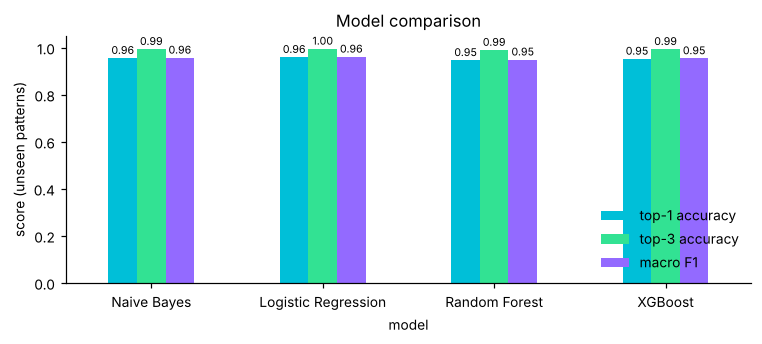

In [7]:
fig, ax = plt.subplots(figsize=(7, 3.2))
comparison[["top-1 accuracy", "top-3 accuracy", "macro F1"]].plot.bar(ax=ax, rot=0, color=["#00BFD8", "#32E293", "#936AFF"])
ax.set_ylim(0, 1.05); ax.set_ylabel("score (unseen patterns)"); ax.set_title("Model comparison")
ax.legend(loc="lower right", frameon=False)
for c in ax.containers: ax.bar_label(c, fmt="%.2f", fontsize=7, padding=1)
plt.tight_layout(); plt.savefig(REPORTS / "model_comparison.png"); plt.show()

### Why XGBoost?
All four models are within about 1 % of each other on unseen patterns, so accuracy alone does not decide.
We choose **XGBoost** because:
- its probabilities are reliable (second-lowest log loss, and calibration below confirms it),
- it gives **exact per-prediction explanations** with TreeSHAP (`pred_contribs`), shown to the doctor,
- unlike Naive Bayes it does not assume symptoms are independent of each other,
- it predicts in a few milliseconds, fast enough for a live consultation.

**Limitation (say this in the defense):** the dataset is synthetic and small (304 distinct patterns).
These numbers measure how well the model generalises *within* this dataset; real-world accuracy must be
checked on real, doctor-confirmed consultations — which the app collects every time a doctor confirms
or rejects a suggestion.

## 6. Calibrate XGBoost probabilities (temperature scaling)
Raw probabilities of boosted trees are often over-confident. We learn one temperature *T*
on the calibration patterns: `p = softmax(logits / T)` (Guo et al., 2017).

In [8]:
booster_model = fitted["XGBoost"]
def logits(model, X):
    return model.predict(X, output_margin=True)

def softmax(z):
    z = z - z.max(1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(1, keepdims=True)

cal_logits = logits(booster_model, X_cal)
nll = lambda T: log_loss(yc, softmax(cal_logits / T), labels=range(len(DISEASES)))
TEMPERATURE = float(minimize_scalar(nll, bounds=(0.3, 10), method="bounded").x)

def ece(proba, y_true, bins=10):
    conf = proba.max(1); correct = proba.argmax(1) == y_true
    edges = np.linspace(0, 1, bins + 1); e = 0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any(): e += m.mean() * abs(correct[m].mean() - conf[m].mean())
    return e

test_logits = logits(booster_model, X_test)
p_raw, p_cal = softmax(test_logits), softmax(test_logits / TEMPERATURE)
print(f"temperature T = {TEMPERATURE:.3f}")
print(f"expected calibration error  before {ece(p_raw, yt):.3f}  →  after {ece(p_cal, yt):.3f}")
print(f"log loss                    before {log_loss(yt, p_raw, labels=range(len(DISEASES))):.3f}  →  after {log_loss(yt, p_cal, labels=range(len(DISEASES))):.3f}")

temperature T = 0.899
expected calibration error  before 0.010  →  after 0.008
log loss                    before 0.142  →  after 0.141


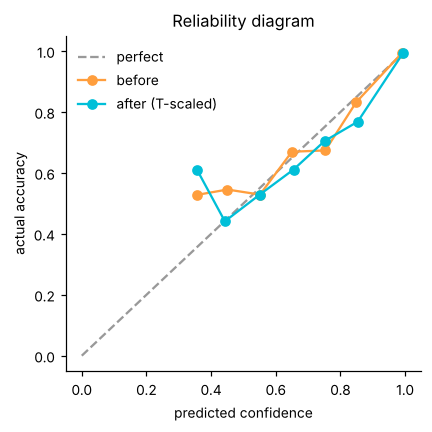

In [9]:
def reliability(ax, proba, y_true, label, color):
    conf = proba.max(1); correct = proba.argmax(1) == y_true
    edges = np.linspace(0, 1, 11); xs, ys = [], []
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.sum() > 20: xs.append(conf[m].mean()); ys.append(correct[m].mean())
    ax.plot(xs, ys, "o-", label=label, color=color)
fig, ax = plt.subplots(figsize=(4, 4))
ax.plot([0, 1], [0, 1], "--", color="#999", label="perfect")
reliability(ax, p_raw, yt, "before", "#FF9E3D"); reliability(ax, p_cal, yt, "after (T-scaled)", "#00BFD8")
ax.set_xlabel("predicted confidence"); ax.set_ylabel("actual accuracy"); ax.set_title("Reliability diagram"); ax.legend(frameon=False)
plt.tight_layout(); plt.savefig(REPORTS / "calibration.png"); plt.show()

## 7. Robustness: how accuracy changes with how many symptoms the patient mentions

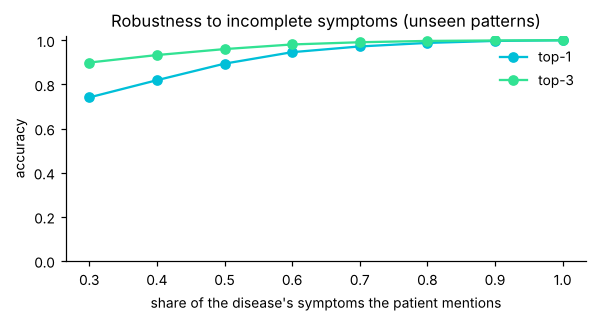

,share of symptoms mentioned,top-1,top-3
0,0.3,0.741,0.899
1,0.4,0.819,0.933
2,0.5,0.894,0.960
3,0.6,0.946,0.981
4,0.7,0.972,0.991
5,0.8,0.988,0.997
6,0.9,0.997,0.999
7,1.0,1.000,1.000


In [10]:
rows = []
for keep in [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]:
    Xk, yk = augment(test_pat, 60, np.random.default_rng(11), keep_range=(keep, keep), noise_p=0.0, min_keep=1)
    pk = softmax(logits(booster_model, Xk) / TEMPERATURE)
    yk_i = enc(yk)
    rows.append({"share of symptoms mentioned": keep,
                 "top-1": accuracy_score(yk_i, pk.argmax(1)),
                 "top-3": top_k_accuracy_score(yk_i, pk, k=3, labels=range(len(DISEASES)))})
robust = pd.DataFrame(rows).round(3)
fig, ax = plt.subplots(figsize=(5.5, 3))
ax.plot(robust.iloc[:, 0], robust["top-1"], "o-", color="#00BFD8", label="top-1")
ax.plot(robust.iloc[:, 0], robust["top-3"], "o-", color="#32E293", label="top-3")
ax.set_ylim(0, 1.02); ax.set_xlabel("share of the disease's symptoms the patient mentions"); ax.set_ylabel("accuracy")
ax.set_title("Robustness to incomplete symptoms (unseen patterns)"); ax.legend(frameon=False)
plt.tight_layout(); plt.savefig(REPORTS / "robustness.png"); plt.show()
robust

## 8. Confusion matrix (calibrated XGBoost, unseen patterns)

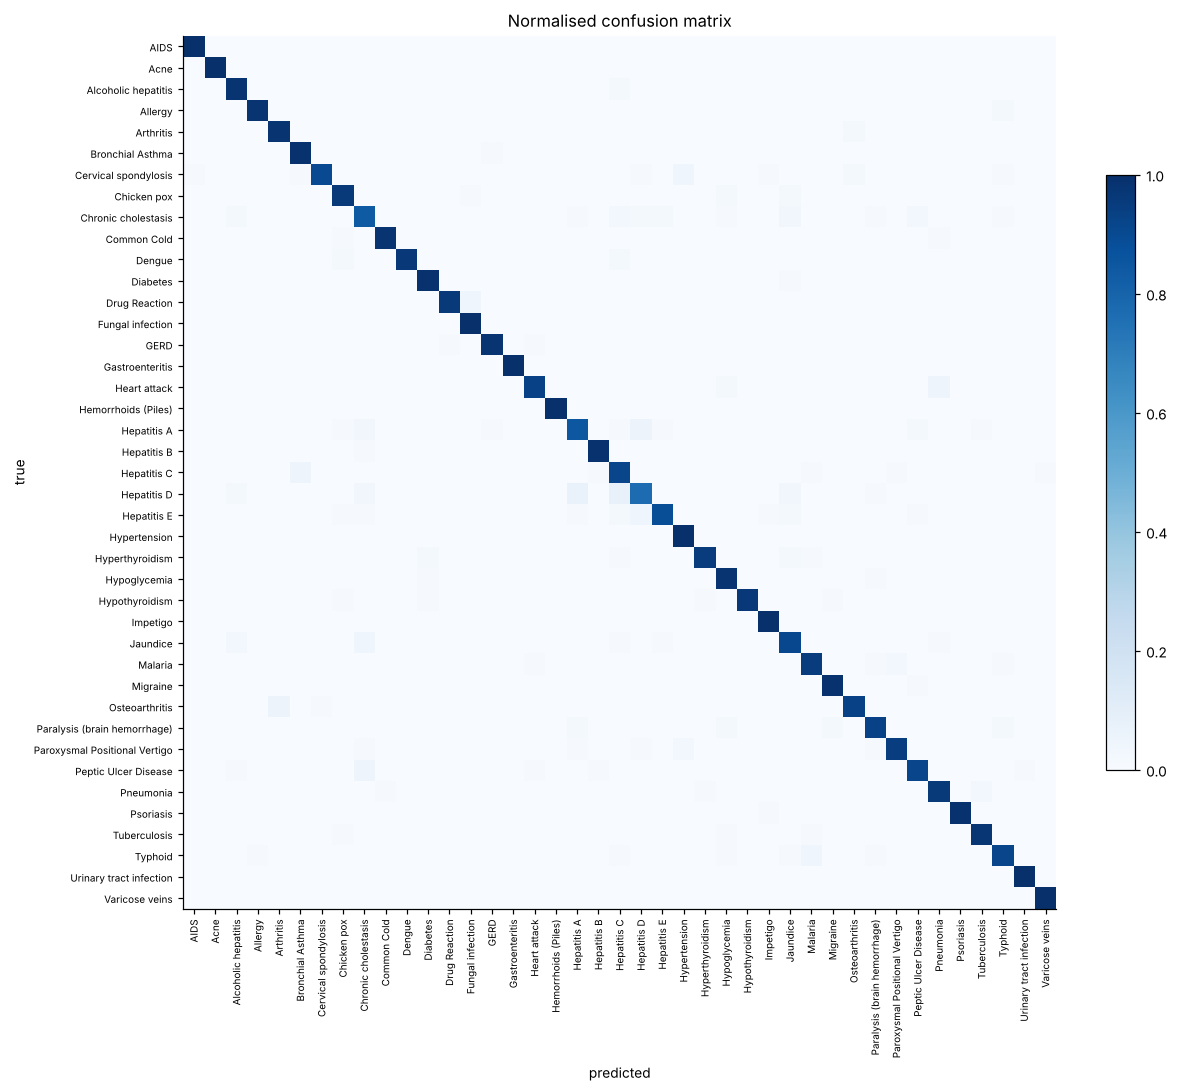

hardest diseases (recall):
Hepatitis D             0.77
Chronic cholestasis     0.83
Hepatitis A             0.85
Hepatitis E             0.88
Cervical spondylosis    0.90
Jaundice                0.91


In [11]:
cm = confusion_matrix(yt, p_cal.argmax(1), labels=range(len(DISEASES)))
cm_norm = cm / cm.sum(1, keepdims=True)
fig, ax = plt.subplots(figsize=(11, 10))
im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(DISEASES))); ax.set_yticks(range(len(DISEASES)))
ax.set_xticklabels(DISEASES, rotation=90, fontsize=6.5); ax.set_yticklabels(DISEASES, fontsize=6.5)
ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title("Normalised confusion matrix")
fig.colorbar(im, fraction=0.03)
plt.tight_layout(); plt.savefig(REPORTS / "confusion_matrix.png"); plt.show()
per_class = pd.Series(np.diag(cm_norm), index=DISEASES).sort_values()
print("hardest diseases (recall):"); print(per_class.head(6).round(2).to_string())

## 9. Explainability with SHAP
Global view: which symptoms matter most overall. Local view: why one case was diagnosed.

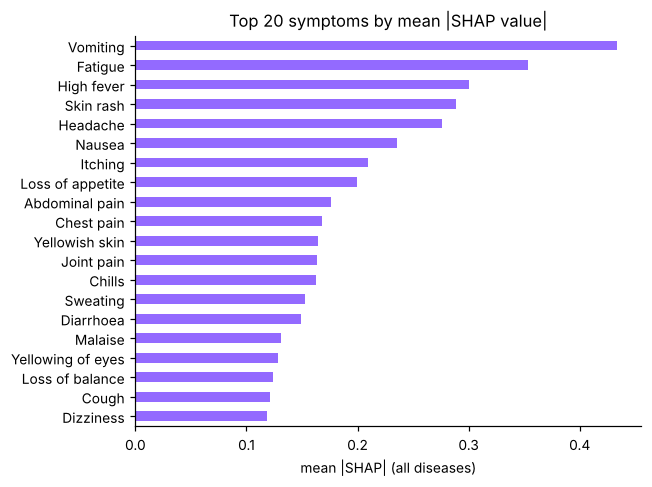

In [12]:
explainer = shap.TreeExplainer(booster_model)
sample = X_test[np.random.default_rng(3).choice(len(X_test), 400, replace=False)]
sv = explainer.shap_values(sample)              # (n, symptoms, classes)
sv = np.array(sv)
if sv.ndim == 3 and sv.shape[0] == len(DISEASES):   # older shap: list per class
    sv = np.transpose(sv, (1, 2, 0))
global_imp = pd.Series(np.abs(sv).mean(axis=(0, 2)), index=[symptom_label(s) for s in SYMPTOMS]).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(6, 4.5))
global_imp.head(20)[::-1].plot.barh(ax=ax, color="#936AFF")
ax.set_title("Top 20 symptoms by mean |SHAP value|"); ax.set_xlabel("mean |SHAP| (all diseases)")
plt.tight_layout(); plt.savefig(REPORTS / "shap_global.png"); plt.show()

In [13]:
def explain_case(symptom_keys, model, top_k=3, top_features=4):
    x = np.zeros((1, len(SYMPTOMS)), dtype=np.int8)
    for s in symptom_keys: x[0, SYMPTOMS.index(s)] = 1
    p = softmax(logits(model, x) / TEMPERATURE)[0]
    contrib = model.get_booster().predict(xgb.DMatrix(x), pred_contribs=True)[0]   # (classes, symptoms+1)
    out = []
    for k in p.argsort()[::-1][:top_k]:
        c = contrib[k][:-1]
        reasons = [(symptom_label(SYMPTOMS[j]), round(float(c[j]), 2)) for j in np.argsort(-c) if x[0, j] and c[j] > 0][:top_features]
        out.append((DISEASES[k], round(float(p[k]) * 100, 1), reasons))
    return out

for d, pct, why in explain_case(["chest_pain", "headache", "dizziness", "lack_of_concentration"], booster_model):
    print(f"{d:<28} {pct:5.1f}%   because: {why}")

Hypertension                 100.0%   because: [('Lack of concentration', 3.79), ('Dizziness', 2.74), ('Chest pain', 2.47), ('Headache', 2.14)]
Pneumonia                      0.0%   because: [('Chest pain', 2.02), ('Dizziness', 1.22)]
Heart attack                   0.0%   because: [('Chest pain', 2.97)]


## 10. Final model: train on ALL patterns and export
The evaluation above used held-out patterns. For deployment we retrain on every pattern
(same settings, same temperature) so no disease pattern is wasted.

In [14]:
X_all_aug, y_all_aug = augment(patterns, 80, np.random.default_rng(SEED))
final = xgb.XGBClassifier(**XGB_PARAMS)
final.fit(X_all_aug, enc(y_all_aug))
final.save_model(EXPORT / "diagnosis_xgb.ubj")

desc = pd.read_csv(DATA / "symptom_Description.csv", header=None, names=["disease", "description"])
prec = pd.read_csv(DATA / "symptom_precaution.csv", header=None)
sev = pd.read_csv(DATA / "Symptom_severity.csv", header=None, names=["symptom", "weight"])
norm = lambda s: re.sub(r"[^a-z]", "", clean_disease(str(s)).lower())
desc_map = {norm(r.disease): r.description.strip() for r in desc.itertuples()}
prec_map = {norm(r[1]): [str(v).strip().capitalize() for v in r[2:] if isinstance(v, str) and v.strip()] for r in prec.itertuples()}

def lookup(table, disease):
    key = norm(disease)
    if key in table: return table[key]
    close = get_close_matches(key, list(table), n=1, cutoff=0.6)   # e.g. spelling differences
    return table[close[0]] if close else None
sev_map = {str(r.symptom).strip(): int(r.weight) for r in sev.itertuples()}

meta = {
    "version": time.strftime("%Y-%m-%d"),
    "temperature": TEMPERATURE,
    "symptoms": [{"key": s, "label": symptom_label(s), "severity": sev_map.get(s, 3)} for s in SYMPTOMS],
    "diseases": [{"name": d, "description": lookup(desc_map, d) or "", "precautions": lookup(prec_map, d) or []} for d in DISEASES],
    "evaluation": {
        "note": "Held-out unseen symptom patterns, 30-100% of symptoms mentioned, 0-2 unrelated symptoms added",
        "xgboost": {k: float(v) for k, v in comparison.loc["XGBoost"].items()},
        "calibrated_ece": float(ece(p_cal, yt)),
        "robustness": robust.to_dict(orient="records"),
    },
}
(EXPORT / "model_meta.json").write_text(json.dumps(meta, indent=2))
comparison.to_csv(REPORTS / "model_comparison.csv"); robust.to_csv(REPORTS / "robustness.csv", index=False)
missing = [d["name"] for d in meta["diseases"] if not d["description"]]
print("exported to", EXPORT, "| diseases without description:", missing or "none")

exported to ../backend/ai_service/model | diseases without description: none


## 11. Quick check of the exported model

In [15]:
check = xgb.XGBClassifier(); check.load_model(EXPORT / "diagnosis_xgb.ubj")
for d, pct, why in explain_case(["high_fever", "headache", "nausea", "pain_behind_the_eyes", "joint_pain", "skin_rash"], check):
    print(f"{d:<28} {pct:5.1f}%   because: {why}")

Dengue                       100.0%   because: [('Pain behind the eyes', 3.71), ('Skin rash', 1.94), ('Joint pain', 1.6), ('Nausea', 1.12)]
Psoriasis                      0.0%   because: [('Joint pain', 2.84), ('Skin rash', 2.22)]
Chicken pox                    0.0%   because: [('Headache', 1.51), ('Skin rash', 1.41), ('High fever', 1.03)]
